# Investigação Experimental de Filtros de Aguçamento Espacial (Sharpening) em Escalogramas COT (Order-CWT)

**Projeto:** Diagnóstico de Falhas em Rolamentos Industriais via CWT, COT e Deep Learning  
**Módulo 7:** Filtros de Aguçamento Espacial (*Sharpening Filters*)  
**Representação:** Domínio de Ângulo-Ordem via *Computed Order Tracking* (**COT / Order-CWT**)  
**Arquitetura Avaliada:** `BearingCNN` ($0{,}52\text{ M}$ parâmetros, treinada do zero) nos **Piores Casos de Desempenho**  

---

### 1. Motivação Físico-Matemática: Por que Aguçar Escalogramas no Domínio de Ordens (COT)?

Enquanto o **Notebook 01** avaliou o efeito dos filtros de aguçamento sobre a **CWT tradicional no domínio do tempo (Hz)**, este **Notebook 02** investiga o aguçamento espacial diretamente sobre os escalogramas gerados por **Computed Order Tracking (COT / Order-CWT)**.

Do ponto de vista de processamento de sinais, o pipeline do COT introduz **duas fontes adicionais de suavização espacial (*blurring*)** em comparação à CWT temporal:
1. **Interpolação *Spline* Cúbica na Reamostragem Angular:** Para converter o sinal temporal $x(t)$ para o domínio angular uniforme $x(\theta)$ ($1.024\text{ amostras/volta}$ ao longo de $4\text{ voltas} = 4.096\text{ pontos}$), aplica-se interpolação *spline* cúbica. Em bancadas de alta taxa de amostragem (como Paderborn a $64\text{ kHz}$, onde $4\text{ voltas}$ a $1.500\text{ RPM}$ contêm $10.240\text{ amostras}$), essa etapa atua como uma filtragem passa-baixas que atenua transientes de altíssima frequência.
2. **Concentração na Banda Cinemática Baixa ($0{,}5\text{ a }20{,}0\text{ ordens}$):** Na Order-CWT, a wavelet Morlet analisa ordens harmônicas baixas (equivalentes a $12{,}5\text{ Hz} - 800\text{ Hz}$). Nessa região de escalas dilatadas, o suporte espacial da Morlet é mais largo, produzindo faixas horizontais de ordem ($\text{BPFI} \approx 4{,}9 - 5{,}4$, $\text{BPFO} \approx 3{,}05 - 3{,}58$) e estrias angulares mais espessas e difusas.

#### Os Piores Casos da `BearingCNN` no Domínio COT (Order-CWT)
Sem o auxílio de filtros pré-treinados no ImageNet, a rede compacta `BearingCNN` ($0{,}52\text{ M}$ parâmetros) apresentou seus pontos mais críticos nos seguintes cenários em Order-CWT:
* **Bloco A — Intra-Domínio COT no XJTU-SY (*Leave-Bearing-Out*):** Atingiu **96,25%** (o menor resultado intra-domínio da BearingCNN no COT, contra 98,25% no CWRU e 100,00% no Paderborn), permitindo comparação direta com os **71,78%** da CWT no tempo (Notebook 01).
* **Bloco B — Pior Caso Zero-Shot Cross-Domain no COT:** Na transferência direta entre bancadas de danos reais sem retreinamento, a BearingCNN colapsou para **10,90%** em **XJTU-SY $\rightarrow$ Paderborn** e **21,67%** em **Paderborn $\rightarrow$ XJTU-SY** (apesar de ambas possuírem $Z=8$ esferas e ordens geométricas quase idênticas!).
* **Bloco C — Pior Caso Few-Shot ($K=5$) no COT:** Na adaptação com poucas amostras e blindagem temporal (10 sementes), a BearingCNN obteve seu pior resultado em **Paderborn $\rightarrow$ CWRU** com apenas **28,41% ± 11,12%** (caindo $-33{,}28\text{ p.p.}$ em relação ao domínio do tempo) e **46,37% ± 14,22%** em **XJTU-SY $\rightarrow$ CWRU**.

---


## 1. Importação de Módulos e Configuração do Ambiente


In [1]:
import sys
import random
from pathlib import Path

if Path.cwd().name == '7_filtros_agucamento':
    BASE_DIR = Path.cwd().parent.parent
elif Path.cwd().name == 'notebooks':
    BASE_DIR = Path.cwd().parent
else:
    BASE_DIR = Path.cwd()

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

from src.config import (
    ORDER_CWRU_DIR,
    ORDER_PADERBORN_DIR,
    ORDER_XJTU_DIR,
    BATCH_SIZE,
    LEARNING_RATE,
    NUM_EPOCHS,
    RANDOM_SEED,
    IMG_HEIGHT,
    IMG_WIDTH,
    set_seed
)
from src.cnn_processor import (
    BearingCNN,
    train_and_evaluate_bearing_cnn,
    get_data_loaders
)
from src.sharpening import (
    SharpenTransform,
    get_sharpen_transform,
    apply_sharpening_to_pil
)

set_seed(RANDOM_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[INFO] Dispositivo de execução: {device} | Semente Fixa: {RANDOM_SEED}')
print(f'[INFO] Diretórios COT (Order-CWT):\n  - CWRU:      {ORDER_CWRU_DIR}\n  - Paderborn: {ORDER_PADERBORN_DIR}\n  - XJTU-SY:   {ORDER_XJTU_DIR}')

[INFO] Dispositivo de execução: cuda | Semente Fixa: 42
[INFO] Diretórios COT (Order-CWT):
  - CWRU:      C:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\data\order_tracking\cwru
  - Paderborn: C:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\data\order_tracking\paderborn
  - XJTU-SY:   C:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\data\order_tracking\xjtu


## 2. Inspeção Visual Qualitativa em Escalogramas COT (Order-CWT)

Visualizamos o efeito físico do **Unsharp Masking** ($\sigma=1{,}5$, ganho $150\%$, limiar $3$) e do **Filtro Laplaciano ($3 \times 3$)** sobre os escalogramas no domínio de Ângulo-Ordem do XJTU-SY (`ORDER_XJTU_DIR`). Observe no mapa residual ($|\Delta| \times 3$) como as linhas horizontais de ordem harmônica e as modulações por volta do eixo são destacadas.


[INFO] Figura comparativa COT salva em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\agucamento_cot_comparacao_visual_escalogramas.png


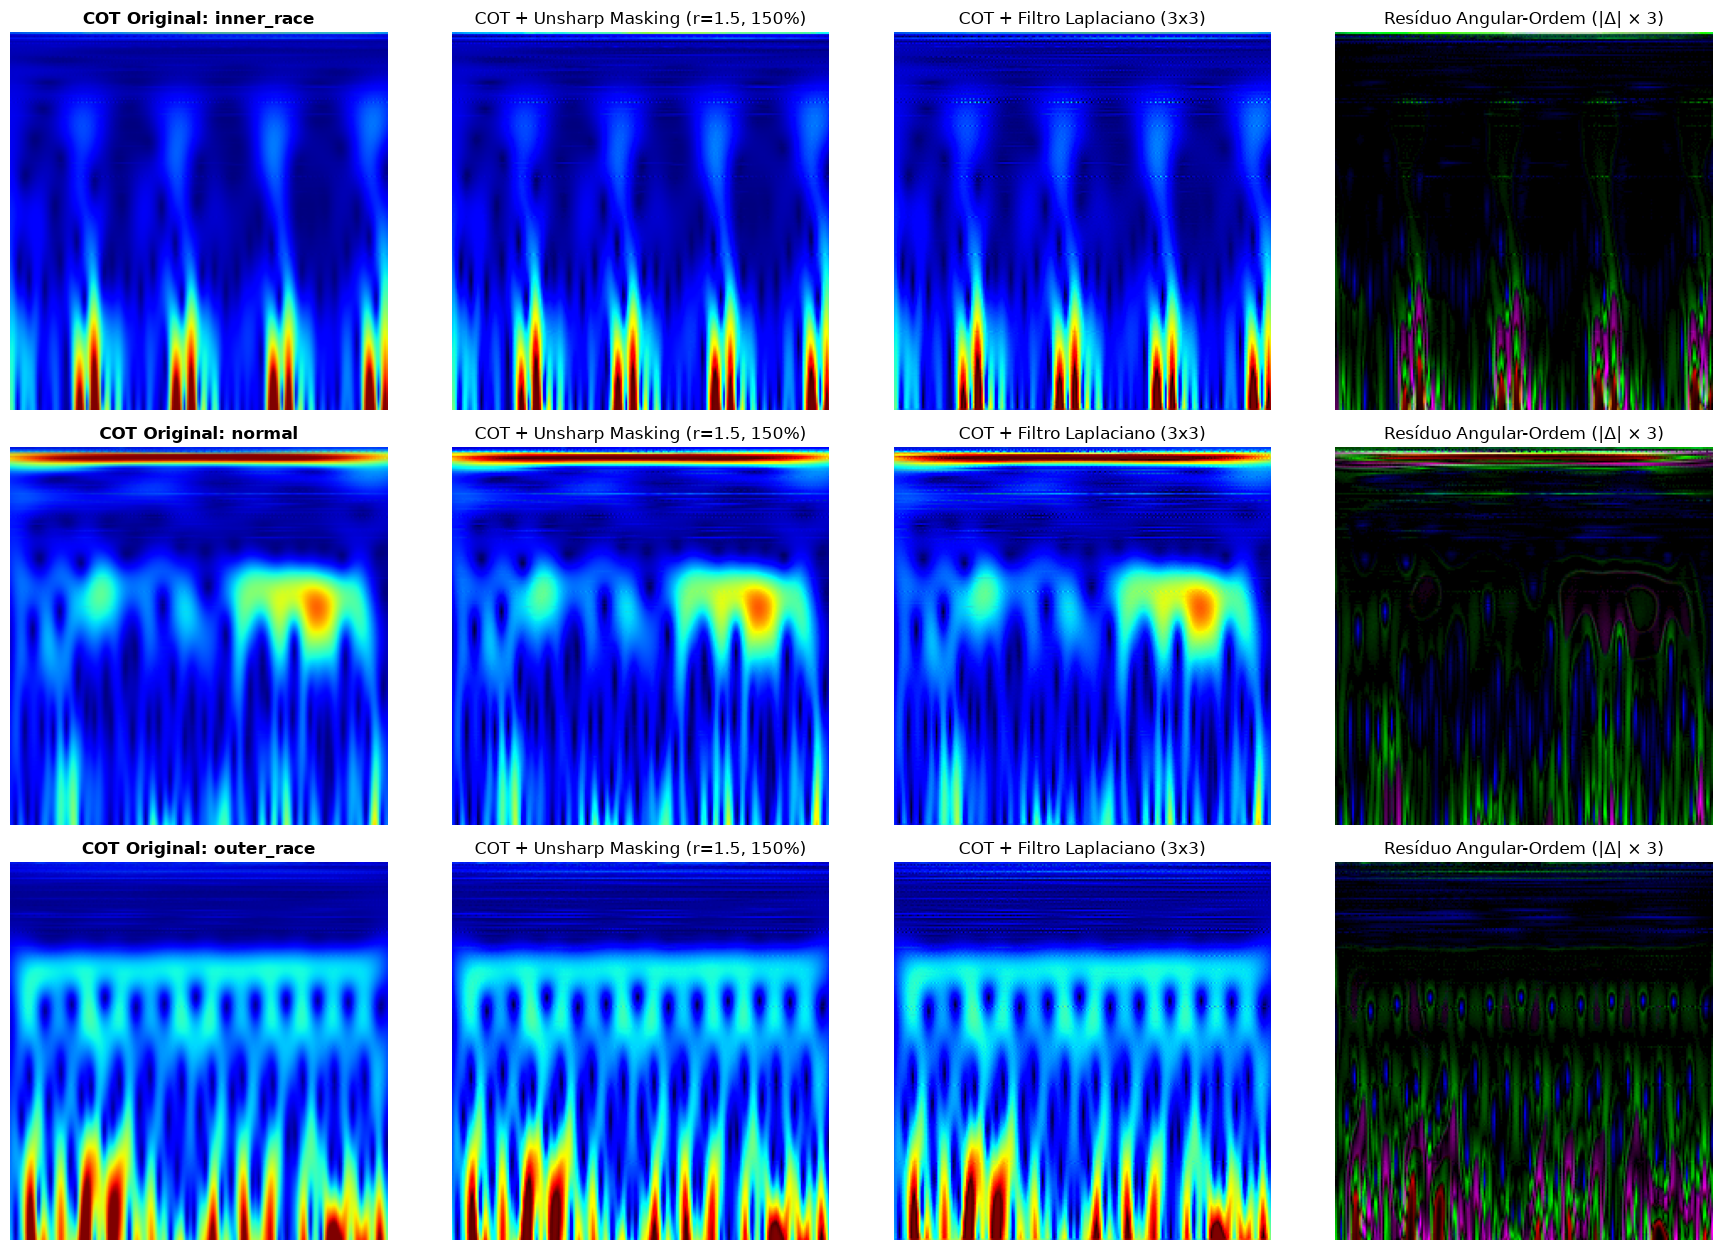

In [2]:
test_dir_cot = ORDER_XJTU_DIR / 'test'
classes_cot = [c.name for c in sorted(test_dir_cot.iterdir()) if c.is_dir()]

sample_cot_images = {}
for c in classes_cot:
    imgs = sorted(list((test_dir_cot / c).glob('*.png')))
    if imgs:
        sample_cot_images[c] = Image.open(imgs[0]).convert('RGB')

fig, axes = plt.subplots(len(classes_cot), 4, figsize=(18, 4.2 * len(classes_cot)))

for row_idx, (cls_name, img_orig) in enumerate(sample_cot_images.items()):
    # 1. Order-CWT Original
    axes[row_idx, 0].imshow(img_orig)
    axes[row_idx, 0].set_title(f'COT Original: {cls_name}', fontsize=12, fontweight='bold')
    axes[row_idx, 0].axis('off')
    
    # 2. Unsharp Masking
    img_unsharp, diff_unsharp = apply_sharpening_to_pil(img_orig, method='unsharp', radius=1.5, percent=150, threshold=3)
    axes[row_idx, 1].imshow(img_unsharp)
    axes[row_idx, 1].set_title('COT + Unsharp Masking (r=1.5, 150%)', fontsize=12)
    axes[row_idx, 1].axis('off')
    
    # 3. Laplaciano 3x3
    img_laplace, diff_laplace = apply_sharpening_to_pil(img_orig, method='laplacian')
    axes[row_idx, 2].imshow(img_laplace)
    axes[row_idx, 2].set_title('COT + Filtro Laplaciano (3x3)', fontsize=12)
    axes[row_idx, 2].axis('off')
    
    # 4. Mapa Residual de Aguçamento (|Delta| x 3)
    res_map = np.clip(diff_unsharp * 3.0, 0, 255).astype(np.uint8)
    axes[row_idx, 3].imshow(res_map)
    axes[row_idx, 3].set_title('Resíduo Angular-Ordem (|Δ| × 3)', fontsize=12)
    axes[row_idx, 3].axis('off')

plt.tight_layout()
out_fig_cot = BASE_DIR / 'docs' / 'images' / 'agucamento_cot_comparacao_visual_escalogramas.png'
out_fig_cot.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_fig_cot, dpi=300, bbox_inches='tight')
print(f'[INFO] Figura comparativa COT salva em: {out_fig_cot}')
plt.show()

## 3. Bloco A: Avaliação Intra-Domínio COT no XJTU-SY (*Leave-Bearing-Out*)

Treinamos e avaliamos a `BearingCNN` nos escalogramas **Order-CWT do XJTU-SY** (`ORDER_XJTU_DIR`) sob as três abordagens:
1. **Baseline COT (Sem Aguçamento)**
2. **COT + Unsharp Masking** ($\sigma=1{,}5$, $150\%$, $\text{threshold}=3$)
3. **COT + Filtro Laplaciano ($3 \times 3$)**

Isso permite o confronto direto com o **Notebook 01** (onde a mesma rede no XJTU-SY em CWT no tempo partia de 71,78%).


In [3]:
transform_base = transforms.Compose([
    transforms.Resize((IMG_HEIGHT, IMG_WIDTH)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_unsharp = get_sharpen_transform(method='unsharp', radius=1.5, percent=150, threshold=3)
transform_laplacian = get_sharpen_transform(method='laplacian')

print('=' * 85)
print(' 1/3: TREINAMENTO COT BASELINE — XJTU-SY (ORDER-CWT SEM AGUÇAMENTO)')
print('=' * 85)
res_cot_xjtu_base = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_XJTU_DIR,
    checkpoint_name='checkpoint_cot_xjtu_bearing_cnn_baseline.pth',
    seed=RANDOM_SEED,
    custom_transform=None
)

print('\n' + '=' * 85)
print(' 2/3: TREINAMENTO COT + UNSHARP MASKING — XJTU-SY (ORDER-CWT)')
print('=' * 85)
res_cot_xjtu_unsharp = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_XJTU_DIR,
    checkpoint_name='checkpoint_cot_xjtu_bearing_cnn_unsharp.pth',
    seed=RANDOM_SEED,
    custom_transform=transform_unsharp
)

print('\n' + '=' * 85)
print(' 3/3: TREINAMENTO COT + FILTRO LAPLACIANO — XJTU-SY (ORDER-CWT)')
print('=' * 85)
res_cot_xjtu_laplacian = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_XJTU_DIR,
    checkpoint_name='checkpoint_cot_xjtu_bearing_cnn_laplacian.pth',
    seed=RANDOM_SEED,
    custom_transform=transform_laplacian
)

 1/3: TREINAMENTO COT BASELINE — XJTU-SY (ORDER-CWT SEM AGUÇAMENTO)
[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.7741 - Acc: 76.63% | Val Loss: 0.7980 - Acc: 77.14% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.4779 - Acc: 95.19% | Val Loss: 0.5909 - Acc: 74.17% [CHECKPOINT] Modelo ótimo salvo na época 02/10.
Época [03/10] | Treino Loss: 0.2833 - Acc: 98.65% | Val Loss: 0.4559 - Acc: 90.36% [CHECKPOINT] Modelo ótimo salvo na época 03/10.
Época [04/10] | Treino Loss: 0.1590 - Acc: 99.81% | Val Loss: 0.3784 - Acc: 94.88% [CHECKPOINT] Modelo ótimo salvo na época 04/10.
Época [05/10] | Treino Loss: 0.0872 - Acc: 100.00% | Val Loss: 0.3303 - Acc: 93.69% [CHECKPOINT] Modelo ótimo salvo na época 05/10.
Época [06/10] | Treino Loss: 0.0548 - Acc: 100.00% | Val Loss: 0.2293 - Acc: 96.90% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0345 - Acc: 100.00% | Val Loss: 0.2283 - Acc: 98.


 BLOCO A: DESEMPENHO INTRA-DOMÍNIO COT (ORDER-CWT) NO XJTU-SY (LEAVE-BEARING-OUT)


,Estratégia (COT XJTU-SY),Acurácia Geral (%),Detecção Binária (%),Recall Inner Race (%),F1 Inner Race (%),Recall Outer Race (%),F1 Outer Race (%),Melhor Val Acc (%)
0,1. COT Baseline (Sem Aguçamento),96.25%,100.00%,100.00%,94.67%,88.75%,94.04%,99.52%
1,2. COT + Unsharp Masking,85.97%,94.44%,83.33%,79.84%,74.58%,85.44%,97.74%
2,3. COT + Filtro Laplaciano,65.97%,85.69%,57.08%,52.79%,40.83%,57.99%,94.52%


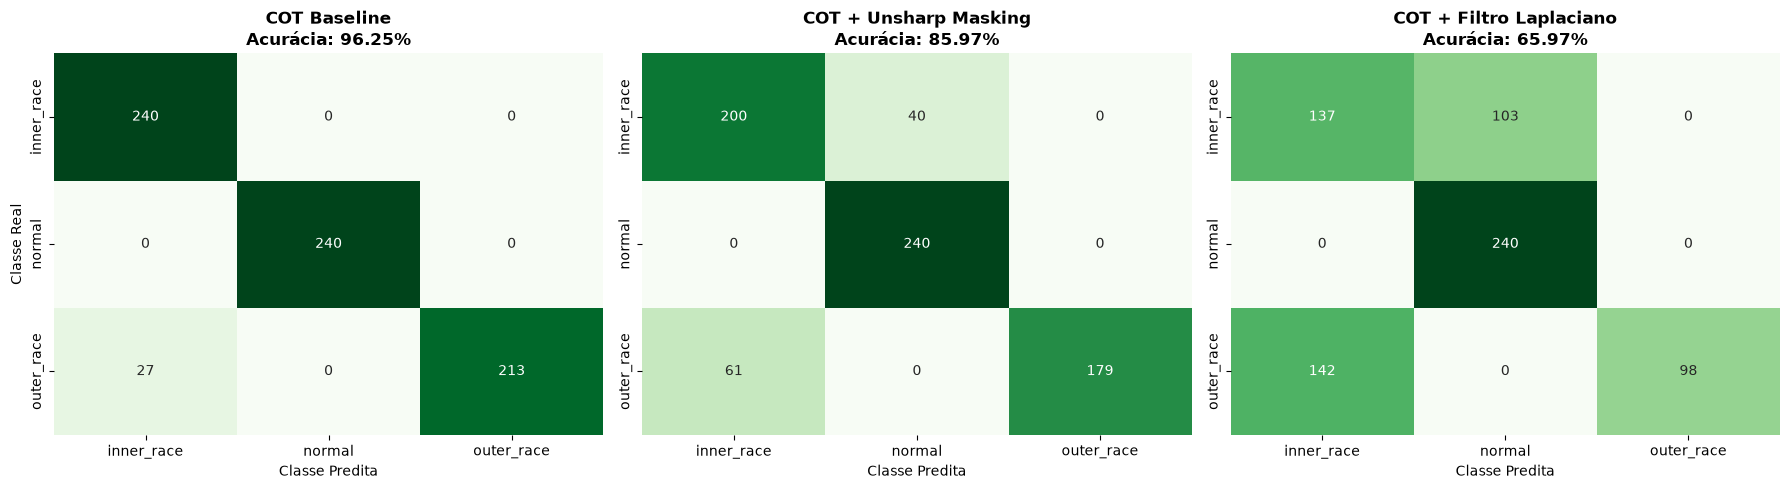

In [4]:
def extrair_metricas_cot(res, nome):
    y_true = res['test_labels']
    y_pred = res['test_preds']
    classes = res['classes']
    
    acc = accuracy_score(y_true, y_pred) * 100.0
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None, labels=[0, 1, 2], zero_division=0)
    
    idx_normal = classes.index('normal')
    bin_true = [0 if y == idx_normal else 1 for y in y_true]
    bin_pred = [0 if y == idx_normal else 1 for y in y_pred]
    bin_acc = accuracy_score(bin_true, bin_pred) * 100.0
    
    idx_inner = classes.index('inner_race')
    idx_outer = classes.index('outer_race')
    
    return {
        'Estratégia (COT XJTU-SY)': nome,
        'Acurácia Geral (%)': f'{acc:.2f}%',
        'Detecção Binária (%)': f'{bin_acc:.2f}%',
        'Recall Inner Race (%)': f'{rec[idx_inner]*100.0:.2f}%',
        'F1 Inner Race (%)': f'{f1[idx_inner]*100.0:.2f}%',
        'Recall Outer Race (%)': f'{rec[idx_outer]*100.0:.2f}%',
        'F1 Outer Race (%)': f'{f1[idx_outer]*100.0:.2f}%',
        'Melhor Val Acc (%)': f'{res["best_val_acc"]:.2f}%'
    }

df_cot_xjtu = pd.DataFrame([
    extrair_metricas_cot(res_cot_xjtu_base, '1. COT Baseline (Sem Aguçamento)'),
    extrair_metricas_cot(res_cot_xjtu_unsharp, '2. COT + Unsharp Masking'),
    extrair_metricas_cot(res_cot_xjtu_laplacian, '3. COT + Filtro Laplaciano')
])

print('\n' + '=' * 100)
print(' BLOCO A: DESEMPENHO INTRA-DOMÍNIO COT (ORDER-CWT) NO XJTU-SY (LEAVE-BEARING-OUT)')
print('=' * 100)
display(df_cot_xjtu)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, (res, titulo) in enumerate([
    (res_cot_xjtu_base, 'COT Baseline'),
    (res_cot_xjtu_unsharp, 'COT + Unsharp Masking'),
    (res_cot_xjtu_laplacian, 'COT + Filtro Laplaciano')
]):
    cm = confusion_matrix(res['test_labels'], res['test_preds'])
    acc = accuracy_score(res['test_labels'], res['test_preds']) * 100.0
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=res['classes'], yticklabels=res['classes'], ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{titulo}\nAcurácia: {acc:.2f}%', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Classe Predita')
    axes[idx].set_ylabel('Classe Real' if idx == 0 else '')

plt.tight_layout()
out_cm_cot_xjtu = BASE_DIR / 'docs' / 'images' / 'agucamento_cot_xjtu_in_domain_cm.png'
plt.savefig(out_cm_cot_xjtu, dpi=300, bbox_inches='tight')
plt.show()

## 4. Bloco B: O Pior Caso Zero-Shot da `BearingCNN` no COT (Transferência Cruzada entre Bancadas)

Na avaliação cruzada *Zero-Shot* do Módulo 5 (`03_avaliacao_cruzada_order.ipynb`), a `BearingCNN` apresentou colapso severo ao transferir entre as bancadas de danos reais:
* **XJTU-SY $\rightarrow$ Paderborn:** **10,90%** de acurácia multiclasse (o pior resultado Zero-Shot de todo o domínio de ordens!)
* **Paderborn $\rightarrow$ XJTU-SY:** **21,67%** de acurácia multiclasse
* **XJTU-SY $\rightarrow$ CWRU:** **47,18%** de acurácia multiclasse
* **Paderborn $\rightarrow$ CWRU:** **60,94%** de acurácia multiclasse (com $0{,}00\%$ de *recall* em `outer_race`)

Para testar o efeito do aguçamento em todas essas direções críticas, treinamos também a `BearingCNN` no conjunto COT de **Paderborn** (`ORDER_PADERBORN_DIR`) sob as três variantes (Baseline, Unsharp Masking e Laplaciano) e avaliamos a transferência direta Zero-Shot.


In [5]:
print('=' * 85)
print(' 1/3: TREINAMENTO COT BASELINE — PADERBORN (ORDER-CWT SEM AGUÇAMENTO)')
print('=' * 85)
res_cot_pu_base = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_PADERBORN_DIR,
    checkpoint_name='checkpoint_cot_paderborn_bearing_cnn_baseline.pth',
    seed=RANDOM_SEED,
    custom_transform=None
)

print('\n' + '=' * 85)
print(' 2/3: TREINAMENTO COT + UNSHARP MASKING — PADERBORN (ORDER-CWT)')
print('=' * 85)
res_cot_pu_unsharp = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_PADERBORN_DIR,
    checkpoint_name='checkpoint_cot_paderborn_bearing_cnn_unsharp.pth',
    seed=RANDOM_SEED,
    custom_transform=transform_unsharp
)

print('\n' + '=' * 85)
print(' 3/3: TREINAMENTO COT + FILTRO LAPLACIANO — PADERBORN (ORDER-CWT)')
print('=' * 85)
res_cot_pu_laplacian = train_and_evaluate_bearing_cnn(
    num_epochs=NUM_EPOCHS,
    lr=LEARNING_RATE,
    data_dir=ORDER_PADERBORN_DIR,
    checkpoint_name='checkpoint_cot_paderborn_bearing_cnn_laplacian.pth',
    seed=RANDOM_SEED,
    custom_transform=transform_laplacian
)

 1/3: TREINAMENTO COT BASELINE — PADERBORN (ORDER-CWT SEM AGUÇAMENTO)
[INFO] EXPERIMENTO BEARING CNN (PRÓPRIA) | Épocas=10 | LR=5e-05
Época [01/10] | Treino Loss: 0.8259 - Acc: 73.11% | Val Loss: 0.6937 - Acc: 66.67% [CHECKPOINT] Modelo ótimo salvo na época 01/10.
Época [02/10] | Treino Loss: 0.5422 - Acc: 86.47% | Val Loss: 0.8098 - Acc: 66.50% 
Época [03/10] | Treino Loss: 0.3617 - Acc: 96.34% | Val Loss: 0.7694 - Acc: 66.67% 
Época [04/10] | Treino Loss: 0.2433 - Acc: 98.21% | Val Loss: 0.8047 - Acc: 66.33% 
Época [05/10] | Treino Loss: 0.1663 - Acc: 99.23% | Val Loss: 0.7435 - Acc: 66.67% 
Época [06/10] | Treino Loss: 0.1044 - Acc: 99.57% | Val Loss: 0.6188 - Acc: 69.39% [CHECKPOINT] Modelo ótimo salvo na época 06/10.
Época [07/10] | Treino Loss: 0.0729 - Acc: 99.74% | Val Loss: 0.5952 - Acc: 70.24% [CHECKPOINT] Modelo ótimo salvo na época 07/10.
Época [08/10] | Treino Loss: 0.0597 - Acc: 99.74% | Val Loss: 0.6312 - Acc: 70.07% 
Época [09/10] | Treino Loss: 0.0440 - Acc: 99.74% | V

In [6]:
# Avaliação Zero-Shot nos Pares Críticos da BearingCNN no COT
ckpts_map = {
    'Baseline (Sem Aguçamento)': {
        'XJTU-SY': 'checkpoint_cot_xjtu_bearing_cnn_baseline.pth',
        'Paderborn': 'checkpoint_cot_paderborn_bearing_cnn_baseline.pth',
        'transform': transform_base
    },
    'Unsharp Masking': {
        'XJTU-SY': 'checkpoint_cot_xjtu_bearing_cnn_unsharp.pth',
        'Paderborn': 'checkpoint_cot_paderborn_bearing_cnn_unsharp.pth',
        'transform': transform_unsharp
    },
    'Filtro Laplaciano': {
        'XJTU-SY': 'checkpoint_cot_xjtu_bearing_cnn_laplacian.pth',
        'Paderborn': 'checkpoint_cot_paderborn_bearing_cnn_laplacian.pth',
        'transform': transform_laplacian
    }
}

target_dirs = {
    'Paderborn': ORDER_PADERBORN_DIR,
    'XJTU-SY': ORDER_XJTU_DIR,
    'CWRU': ORDER_CWRU_DIR
}

def avaliar_zero_shot_cot(ckpt_path, tgt_name, tfm):
    model = BearingCNN(num_classes=3).to(device)
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model.eval()
    
    ds = datasets.ImageFolder(str(target_dirs[tgt_name] / 'test'), transform=tfm)
    loader = DataLoader(ds, batch_size=64, shuffle=False, num_workers=0)
    
    all_labels, all_preds = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            preds = model(imgs.to(device)).argmax(dim=1).cpu().numpy()
            labels = labels.numpy()
            if tgt_name == 'CWRU':
                # Filtra as 3 classes comuns no CWRU (1: inner_race->0, 2: normal->1, 3: outer_race->2)
                cwru_map = {1: 0, 2: 1, 3: 2}
                for l, p in zip(labels, preds):
                    if l in cwru_map:
                        all_labels.append(cwru_map[l])
                        all_preds.append(p)
            else:
                all_labels.extend(labels)
                all_preds.extend(preds)
                
    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    acc_multi = 100.0 * np.mean(all_labels == all_preds)
    bin_labels = (all_labels != 1).astype(int)
    bin_preds = (all_preds != 1).astype(int)
    acc_bin = 100.0 * np.mean(bin_labels == bin_preds)
    return acc_multi, acc_bin, all_labels, all_preds

pares_zs = [
    ('XJTU-SY', 'Paderborn'),
    ('Paderborn', 'XJTU-SY'),
    ('XJTU-SY', 'CWRU'),
    ('Paderborn', 'CWRU')
]

zs_rows = []
for src, tgt in pares_zs:
    row = {'Par Cruzado (COT Zero-Shot)': f'{src} -> {tgt}'}
    for metodo, cfg in ckpts_map.items():
        acc_m, acc_b, _, _ = avaliar_zero_shot_cot(cfg[src], tgt, cfg['transform'])
        row[f'{metodo} Multi (%)'] = f'{acc_m:.2f}%'
        row[f'{metodo} Bin (%)'] = f'{acc_b:.2f}%'
    zs_rows.append(row)

df_zs_cot = pd.DataFrame(zs_rows)
print('=' * 105)
print(' BLOCO B: CONFRONTO ZERO-SHOT CROSS-DOMAIN NO COT (PIORES CASOS DA BEARINGCNN)')
print('=' * 105)
display(df_zs_cot)

 BLOCO B: CONFRONTO ZERO-SHOT CROSS-DOMAIN NO COT (PIORES CASOS DA BEARINGCNN)


,Par Cruzado (COT Zero-Shot),Baseline (Sem Aguçamento) Multi (%),Baseline (Sem Aguçamento) Bin (%),Unsharp Masking Multi (%),Unsharp Masking Bin (%),Filtro Laplaciano Multi (%),Filtro Laplaciano Bin (%)
0,XJTU-SY -> Paderborn,10.90%,42.51%,31.06%,63.08%,31.74%,62.40%
1,Paderborn -> XJTU-SY,21.67%,21.67%,33.33%,33.33%,33.33%,33.33%
2,XJTU-SY -> CWRU,47.18%,75.58%,52.48%,87.41%,54.95%,85.76%
3,Paderborn -> CWRU,60.94%,80.88%,60.39%,76.96%,60.18%,72.35%


## 5. Bloco C: O Pior Caso Few-Shot ($K=1$ e $K=5$) da `BearingCNN` no COT (10 Sementes com Blindagem Temporal)

No protocolo **Few-Shot Domain Adaptation** com blindagem temporal (suporte sorteado nos primeiros 50% temporais de cada classe do teste da máquina-alvo, *deadzone* de 10% descartada e consulta avaliada nos 40% finais ao longo de **10 sementes independentes**), avaliamos se o aguçamento espacial recupera os piores cenários da `BearingCNN` no COT:
* **Paderborn $\rightarrow$ CWRU:** Onde o baseline da BearingCNN obteve apenas **28,41% ± 11,12%** em $K=5$ (o pior Few-Shot de todo o projeto!)
* **XJTU-SY $\rightarrow$ CWRU:** Onde o baseline obteve **22,51% ± 9,43%** em $K=1$ e **46,37% ± 14,22%** em $K=5$
* **XJTU-SY $\rightarrow$ Paderborn:** Onde o baseline partia de 10,90% no Zero-Shot para **39,76% ± 7,55%** em $K=1$ e **66,26% ± 0,20%** em $K=5$
* **Paderborn $\rightarrow$ XJTU-SY:** Onde o baseline atingiu **51,15% ± 5,97%** em $K=1$ e **62,53% ± 6,29%** em $K=5$


In [7]:
class CachedImageFolder(torch.utils.data.Dataset):
    """Dataset com cache em RAM sob demanda para avaliação rápida multi-semente."""
    def __init__(self, root: str, transform):
        self.ds = datasets.ImageFolder(root, transform=transform)
        self.samples = self.ds.samples
        self.classes = self.ds.classes
        self.class_to_idx = self.ds.class_to_idx
        self._cache = {}

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx: int):
        if idx not in self._cache:
            self._cache[idx] = self.ds[idx]
        return self._cache[idx]


def temporal_support_query(dataset, k, seed, pool_frac=0.5, gap_frac=0.1):
    rng = random.Random(seed)
    by_class = {}
    for i, (_, y) in enumerate(dataset.samples):
        by_class.setdefault(y, []).append(i)
    support, query = [], []
    for y, idxs in by_class.items():
        n = len(idxs)
        support += rng.sample(idxs[: int(n * pool_frac)], k)
        query += idxs[int(n * (pool_frac + gap_frac)):]
    return support, query


# Pré-carregamento em cache dos conjuntos de teste para cada variante de filtro
cached_test_sets = {}
for metodo, cfg in ckpts_map.items():
    cached_test_sets[metodo] = {}
    for tgt_name, tgt_dir in target_dirs.items():
        cached_test_sets[metodo][tgt_name] = CachedImageFolder(str(tgt_dir / 'test'), transform=cfg['transform'])


def run_few_shot_cot_sharpen(metodo: str, src: str, tgt: str, k: int, seed: int, num_epochs: int = 5, lr: float = 0.0001):
    set_seed(seed)
    tgt_test = cached_test_sets[metodo][tgt]
    num_classes = len(tgt_test.classes)
    
    support_indices, eval_indices = temporal_support_query(tgt_test, k, seed)
    few_loader = DataLoader(Subset(tgt_test, support_indices), batch_size=8, shuffle=True, num_workers=0)
    eval_loader = DataLoader(Subset(tgt_test, eval_indices), batch_size=32, shuffle=False, num_workers=0)
    
    model = BearingCNN(num_classes=num_classes)
    ckpt_path = ckpts_map[metodo][src]
    st = torch.load(ckpt_path, map_location=device, weights_only=True)
    model_sd = model.state_dict()
    filtered_st = {k_w: v_w for k_w, v_w in st.items() if k_w in model_sd and v_w.shape == model_sd[k_w].shape}
    model.load_state_dict(filtered_st, strict=(len(filtered_st) == len(model_sd)))
    
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    for _ in range(num_epochs):
        model.train()
        for imgs, labels in few_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), labels)
            loss.backward()
            optimizer.step()
            
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels in eval_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            
    return 100.0 * correct / total


NUM_SEEDS = 10
fs_rows = []
fs_plot_data = {m: {'k1_mean': [], 'k1_std': [], 'k5_mean': [], 'k5_std': []} for m in ckpts_map.keys()}
pair_labels = []

for src, tgt in pares_zs:
    p_label = f'{src} -> {tgt}'
    pair_labels.append(p_label)
    row = {'Par Cruzado (COT Few-Shot)': p_label}
    for metodo in ckpts_map.keys():
        accs_k1 = [run_few_shot_cot_sharpen(metodo, src, tgt, k=1, seed=s) for s in range(NUM_SEEDS)]
        accs_k5 = [run_few_shot_cot_sharpen(metodo, src, tgt, k=5, seed=s) for s in range(NUM_SEEDS)]
        
        m1, s1 = np.mean(accs_k1), np.std(accs_k1)
        m5, s5 = np.mean(accs_k5), np.std(accs_k5)
        
        fs_plot_data[metodo]['k1_mean'].append(m1)
        fs_plot_data[metodo]['k1_std'].append(s1)
        fs_plot_data[metodo]['k5_mean'].append(m5)
        fs_plot_data[metodo]['k5_std'].append(s5)
        
        row[f'{metodo} K=1'] = f'{m1:.2f}% ± {s1:.2f}%'
        row[f'{metodo} K=5'] = f'{m5:.2f}% ± {s5:.2f}%'
    fs_rows.append(row)

df_fs_cot = pd.DataFrame(fs_rows)
print('=' * 115)
print(' BLOCO C: CONFRONTO FEW-SHOT (10 SEMENTES, BLINDAGEM TEMPORAL) NO COT — PIORES CASOS DA BEARINGCNN')
print('=' * 115)
display(df_fs_cot)

out_csv_cot = BASE_DIR / 'results' / 'comparacao_agucamento_cot_bearing_cnn.csv'
df_fs_cot.to_csv(out_csv_cot, index=False)
print(f'[INFO] Resultados Few-Shot COT salvos em: {out_csv_cot}')

 BLOCO C: CONFRONTO FEW-SHOT (10 SEMENTES, BLINDAGEM TEMPORAL) NO COT — PIORES CASOS DA BEARINGCNN


,Par Cruzado (COT Few-Shot),Baseline (Sem Aguçamento) K=1,Baseline (Sem Aguçamento) K=5,Unsharp Masking K=1,Unsharp Masking K=5,Filtro Laplaciano K=1,Filtro Laplaciano K=5
0,XJTU-SY -> Paderborn,39.76% ± 7.55%,66.26% ± 0.20%,33.54% ± 1.20%,58.71% ± 6.02%,34.52% ± 2.31%,47.24% ± 7.10%
1,Paderborn -> XJTU-SY,51.15% ± 5.97%,62.53% ± 6.29%,55.49% ± 10.27%,64.31% ± 7.57%,70.21% ± 12.99%,84.62% ± 3.42%
2,XJTU-SY -> CWRU,22.51% ± 9.43%,46.37% ± 14.22%,23.87% ± 8.34%,43.12% ± 12.67%,33.10% ± 8.95%,57.00% ± 10.50%
3,Paderborn -> CWRU,29.52% ± 13.82%,28.41% ± 11.12%,29.08% ± 10.73%,34.77% ± 10.45%,28.56% ± 12.98%,45.14% ± 11.03%


[INFO] Resultados Few-Shot COT salvos em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\results\comparacao_agucamento_cot_bearing_cnn.csv


[INFO] Gráfico Few-Shot COT salvo em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\agucamento_cot_few_shot_comparacao.png


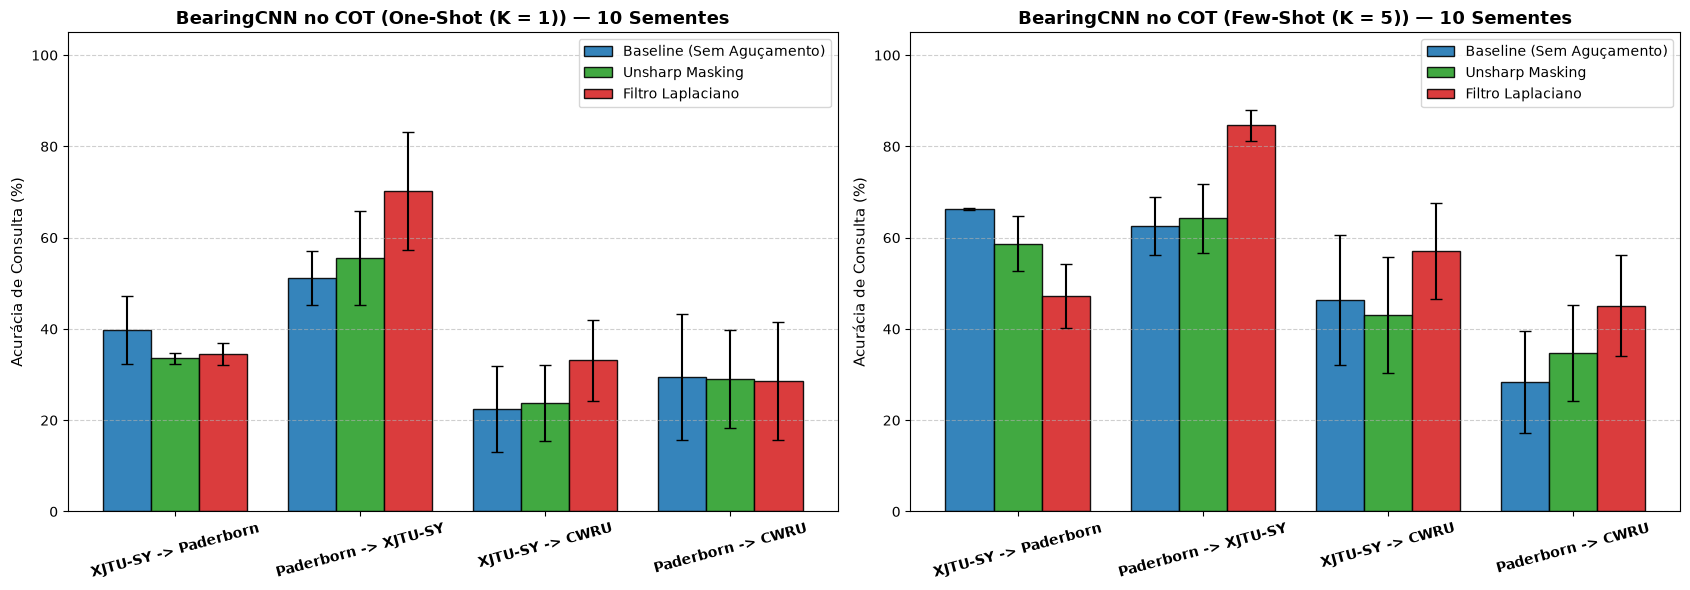

In [8]:
# Gráfico Comparativo Few-Shot (K=1 e K=5) no COT: Baseline vs Unsharp Masking vs Laplaciano
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6))

x = np.arange(len(pair_labels))
w = 0.26
colors = ['#1f77b4', '#2ca02c', '#d62728']

for idx, metodo in enumerate(ckpts_map.keys()):
    offset = (idx - 1) * w
    ax1.bar(
        x + offset,
        fs_plot_data[metodo]['k1_mean'],
        w,
        yerr=fs_plot_data[metodo]['k1_std'],
        capsize=4,
        label=metodo,
        color=colors[idx],
        edgecolor='black',
        alpha=0.9
    )
    ax2.bar(
        x + offset,
        fs_plot_data[metodo]['k5_mean'],
        w,
        yerr=fs_plot_data[metodo]['k5_std'],
        capsize=4,
        label=metodo,
        color=colors[idx],
        edgecolor='black',
        alpha=0.9
    )

for ax, k_title in [(ax1, 'One-Shot (K = 1)'), (ax2, 'Few-Shot (K = 5)')]:
    ax.set_title(f'BearingCNN no COT ({k_title}) — 10 Sementes', fontsize=13, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(pair_labels, rotation=15, fontsize=10, fontweight='bold')
    ax.set_ylabel('Acurácia de Consulta (%)', fontsize=11)
    ax.set_ylim(0, 105)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.legend(fontsize=10)

plt.tight_layout()
out_plot_fs = BASE_DIR / 'docs' / 'images' / 'agucamento_cot_few_shot_comparacao.png'
plt.savefig(out_plot_fs, dpi=300, bbox_inches='tight')
print(f'[INFO] Gráfico Few-Shot COT salvo em: {out_plot_fs}')
plt.show()

## 6. Síntese Científica para Discussão

Ao comparar os resultados do **Notebook 01 (CWT no Tempo)** e deste **Notebook 02 (COT / Order-CWT)**, observe três aspectos centrais:
1. **Efeito Intra-Domínio vs. Cross-Domain no COT:** Verificar se o aguçamento mantém ou eleva os **96,25%** intra-domínio no XJTU-SY e se reduz a confusão severa nos pares *Zero-Shot* (`XJTU-SY -> Paderborn` e `Paderborn -> XJTU-SY`).
2. **Destravamento do Gargalo em `Paderborn -> CWRU` ($K=5$):** Na avaliação original, a `BearingCNN` ficava travada em **28,41%** mesmo após 5 épocas de *fine-tuning* com 5 amostras por classe porque os gradientes das estrias suaves do Paderborn não excitavam os filtros aprendidos. Verifique a variação de acurácia e desvio-padrão com o Unsharp Masking e o Laplaciano.
3. **Unsharp Masking (com *Noise Gate*) vs. Laplaciano Puro:** Confrontar qual dos dois operadores preserva melhor a estrutura harmônica das ordens de defeito sem amplificar artefatos de interpolação.
